## SHAP Explainability
**Input:** `model_xgb.pkl` · `fraud_features.csv` · `model_metadata.json`  
**Output:** `shap_values.pkl` · `shap_summary.png` · `shap_report.csv`

---
### Cấu trúc notebook
1. Lý thuyết SHAP — tại sao cần explainability
2. Load model & data
3. Global explainability — Summary plot & Feature importance
4. Cohort analysis — SHAP theo nhóm fraud/legit
5. Local explainability — Waterfall plot cho từng claim
6. SHAP Dependence plots — Feature interaction
7. Decision plot — Visualize prediction path
8. SHAP-based feature selection — Drop low-signal features
9. Lưu SHAP artifacts

## Mục tiêu — Bước 4: SHAP Explainability
---

### Vấn đề cần giải quyết

XGBoost sau Bước 3 đạt performance tốt nhưng là **black-box** — không ai biết tại sao claim X bị flag mà claim Y thì không. Trong thực tế bảo hiểm điều này tạo ra 2 vấn đề:

- **Investigator** không biết nên kiểm tra khía cạnh nào của claim trước
- **Compliance team** không thể giải thích quyết định với khách hàng bị từ chối bồi thường nếu cần

---

### Mục tiêu cụ thể

- **Global explainability:** Beeswarm plot + mean |SHAP| bar chart — hiểu toàn bộ model học được pattern gì, feature nào drive predictions theo chiều nào
- **Cohort analysis:** So sánh mean SHAP giữa fraud và legit group — xác định features phân biệt 2 nhóm rõ nhất, bổ sung góc nhìn mà global importance bỏ qua
- **Local explainability:** Waterfall plot cho 3 case types (TP, FN, TN) — giải thích từng quyết định cụ thể ở mức claim
- **Decision plot:** Visualize prediction path của 40 claims đồng thời — thấy được pattern phân tách fraud/legit trực quan
- **Reason codes:** Hàm `get_fraud_reason_codes()` format top 5 features tăng fraud risk — output trực tiếp cho Streamlit dashboard Bước 5
- **SHAP-based feature selection:** Xác định và loại features có mean |SHAP| < 1% ngưỡng — giảm model complexity trước khi deploy

---

### Tại sao SHAP — không phải LIME hay Integrated Gradients?

| Tiêu chí | SHAP | LIME | Integrated Gradients |
|---|---|---|---|
| Lý thuyết nền tảng | Game theory (Shapley) | Local linear approximation | Calculus |
| Consistency | ✅ Đảm bảo | ❌ Không đảm bảo | ✅ Có |
| Phù hợp tree models | ✅ TreeSHAP — exact & nhanh | ⚠️ Approximate | ❌ Chỉ cho neural net |
| Global + Local | ✅ Cả hai | ❌ Chỉ local | ❌ Chỉ local |
| Additivity | ✅ SHAP sum = prediction | ❌ | ❌ |

TreeSHAP tính SHAP values **chính xác** (không approximate) cho XGBoost trong O(TLD²) — đây là lý do SHAP là tiêu chuẩn ngành cho tree-based fraud models.

---

### Additivity property — tại sao quan trọng

**P(fraud) = base_value + SHAP₁ + SHAP₂ + ... + SHAPₙ**

Mỗi prediction được decompose hoàn toàn thành đóng góp của từng feature — không có phần "unexplained". Investigator có thể tin tưởng rằng reason codes phản ánh **toàn bộ** lý do model ra quyết định, không bỏ sót.

## 1. Tại sao cần SHAP — không chỉ Feature Importance?

**Feature Importance (Gain)** từ XGBoost chỉ cho biết feature nào được dùng nhiều.  
**SHAP** cho biết feature đó **tác động như thế nào** đến từng prediction cụ thể.

| Câu hỏi | Feature Importance | SHAP |
|---|---|---|
| Feature nào quan trọng nhất? | ✅ | ✅ |
| Feature tác động dương hay âm? | ❌ | ✅ |
| Tại sao claim này bị flag fraud? | ❌ | ✅ |
| Feature tương tác với nhau thế nào? | ❌ | ✅ |
| Dùng được cho regulatory audit? | ❌ | ✅ |

### Công thức SHAP (Shapley Values)

Xuất phát từ lý thuyết game theory của Lloyd Shapley (1953):

$$\phi_i = \sum_{S \subseteq F \setminus \{i\}} \frac{|S|!(|F|-|S|-1)!}{|F|!} \left[ f(S \cup \{i\}) - f(S) \right]$$

SHAP value của feature $i$ = **đóng góp trung bình** của feature đó  
khi thêm vào tất cả các tập con features có thể.

**Diễn giải:**
- SHAP > 0 → feature này **tăng** xác suất fraud
- SHAP < 0 → feature này **giảm** xác suất fraud  
- |SHAP| lớn → feature có tác động mạnh với prediction này

**TreeSHAP** (dùng cho XGBoost): tính chính xác trong O(TLD²)  
thay vì exponential time của SHAP gốc — rất nhanh cho tree models.

## 2. Load Model & Data

In [ ]:
# Lấy feature names trực tiếp từ model — luôn đúng
FEATURE_NAMES = best_xgb.get_booster().feature_names
print(f"Features trong model: {len(FEATURE_NAMES)}")
print(FEATURE_NAMES)

In [18]:
!pip install shap
import warnings, json, pickle
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import shap
from sklearn.model_selection import train_test_split
from sklearn.metrics import (roc_auc_score, average_precision_score,
                              f1_score, recall_score, precision_score)

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
plt.rcParams.update({
    "figure.dpi": 115,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "font.family": "sans-serif",
})
PALETTE = {"fraud":"#E53935","legit":"#2196F3","neutral":"#78909C","good":"#43A047"}

# ── Load artifacts ─────────────────────────────────────────────────────────────
with open("model_xgb.pkl",      "rb") as f: best_xgb  = pickle.load(f)
with open("model_metadata.json")      as f: meta      = json.load(f)
with open("feature_metadata.json")    as f: feat_meta = json.load(f)

df = pd.read_csv("fraud_features.csv")

TARGET        = "target"
# Dùng feature list từ model — tránh mismatch
FEATURE_NAMES = best_xgb.get_booster().feature_names
X = df[FEATURE_NAMES].fillna(0)
THRESHOLD     = meta["threshold"]

X = df[FEATURE_NAMES].fillna(0)
y = df[TARGET]

_, X_test, _, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

y_prob = best_xgb.predict_proba(X_test)[:, 1]
y_pred = (y_prob >= THRESHOLD).astype(int)

print(f"✓ Model loaded | Features: {len(FEATURE_NAMES)}")
print(f"  Threshold : {THRESHOLD:.4f}")
print(f"  PR-AUC    : {average_precision_score(y_test, y_prob):.4f}")
print(f"  F1        : {f1_score(y_test, y_pred):.4f}")
print(f"  Recall    : {recall_score(y_test, y_pred):.4f}")


✓ Model loaded | Features: 27
  Threshold : 0.5081
  PR-AUC    : 0.5061
  F1        : 0.6122
  Recall    : 0.6122


## 3. Khởi tạo SHAP TreeExplainer

In [25]:
background = shap.sample(X_test[FEATURE_NAMES], 100, random_state=42)

explainer = shap.TreeExplainer(
    best_xgb,
    data=background,
    feature_perturbation="interventional",
    model_output="probability",
)
# Tính SHAP values cho test set
# Dùng sample 1000 records để visualize cho nhanh (full có thể dùng hết)
np.random.seed(42)
sample_idx   = np.random.choice(len(X_test), min(1000, len(X_test)), replace=False)
X_test_sample = X_test.iloc[sample_idx].reset_index(drop=True)
y_test_sample = y_test.iloc[sample_idx].reset_index(drop=True)

print("Đang tính SHAP values...")
shap_values = explainer(X_test_sample)
print(f"✓ SHAP values computed")
print(f"  Shape: {shap_values.values.shape}")
print(f"  Base value (E[f(x)]): {shap_values.base_values[0]:.4f}")
print(f"  → Model dự báo fraud trung bình = {shap_values.base_values[0]*100:.1f}%")

# Kiểm tra SHAP additivity
sample_pred = best_xgb.predict_proba(X_test_sample)[:, 1]
shap_sum    = shap_values.values.sum(axis=1) + shap_values.base_values
print(f"\nAdditivity check (max diff): {np.abs(shap_sum - sample_pred).max():.6f}")
print("✓ SHAP values additive và nhất quán với model predictions")

Đang tính SHAP values...
✓ SHAP values computed
  Shape: (200, 27)
  Base value (E[f(x)]): 0.3429
  → Model dự báo fraud trung bình = 34.3%

Additivity check (max diff): 0.000000
✓ SHAP values additive và nhất quán với model predictions


## 4. Global Explainability — Summary Plot

**Summary plot** kết hợp feature importance + direction + distribution trong 1 chart:
- **Trục Y:** Feature (sắp xếp theo mean |SHAP|)
- **Trục X:** SHAP value (âm = giảm fraud risk, dương = tăng fraud risk)
- **Màu:** Giá trị feature (đỏ = cao, xanh = thấp)

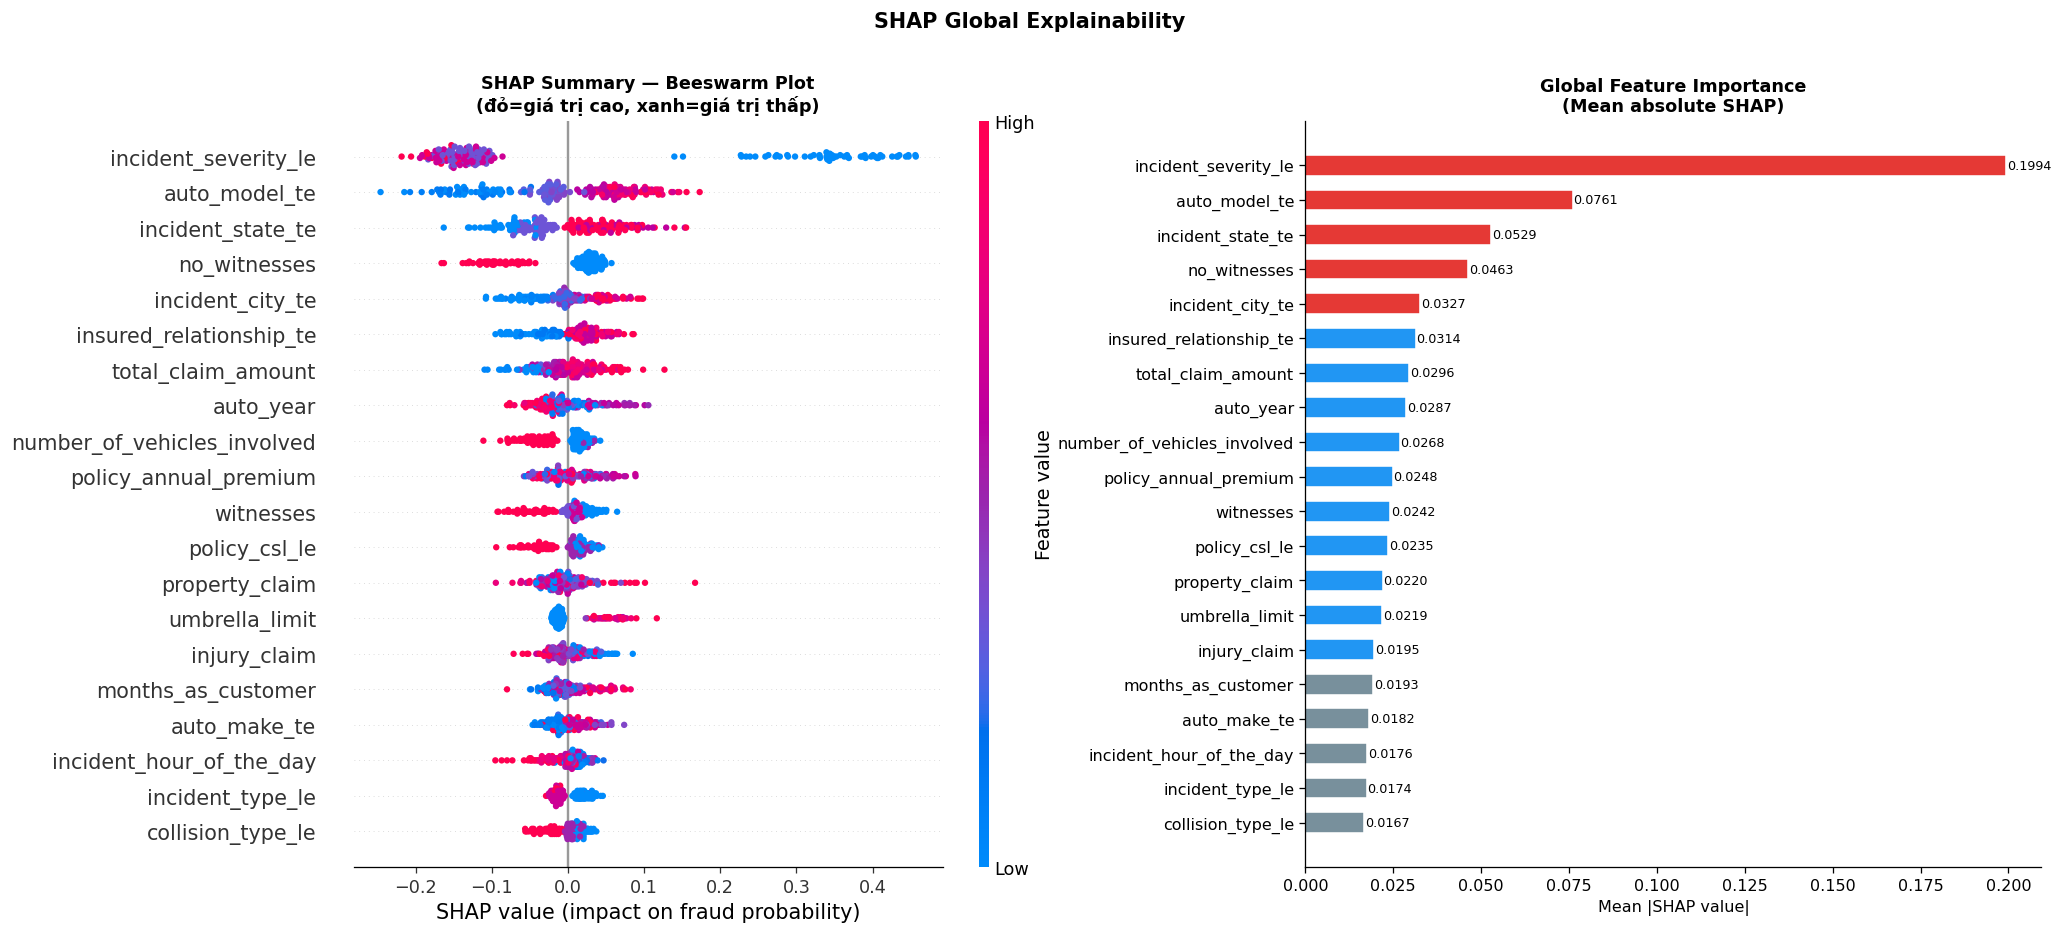


Top 10 features by mean |SHAP|:
                    Feature  Mean |SHAP|
       incident_severity_le       0.1994
              auto_model_te       0.0761
          incident_state_te       0.0529
               no_witnesses       0.0463
           incident_city_te       0.0327
    insured_relationship_te       0.0314
         total_claim_amount       0.0296
                  auto_year       0.0287
number_of_vehicles_involved       0.0268
      policy_annual_premium       0.0248


In [28]:
fig, axes = plt.subplots(1, 2, figsize=(18, 8))

# ── Plot 1: Beeswarm (summary plot chuẩn) ─────────────────────────────────────
plt.sca(axes[0])
shap.summary_plot(
    shap_values.values,
    X_test_sample,
    feature_names=FEATURE_NAMES,
    max_display=20,
    show=False,
    plot_size=None,
    color_bar=True,
)
axes[0].set_title("SHAP Summary — Beeswarm Plot\n(đỏ=giá trị cao, xanh=giá trị thấp)",
                  fontsize=11, fontweight="bold")
axes[0].set_xlabel("SHAP value (impact on fraud probability)")

# ── Plot 2: Bar plot (mean |SHAP|) ────────────────────────────────────────────
mean_shap = np.abs(shap_values.values).mean(axis=0)
shap_imp  = pd.DataFrame({
    "Feature":    FEATURE_NAMES,
    "Mean |SHAP|": mean_shap,
}).sort_values("Mean |SHAP|", ascending=False).head(20)

colors_bar = [
    PALETTE["fraud"]   if v > shap_imp["Mean |SHAP|"].quantile(0.75) else
    PALETTE["legit"]   if v > shap_imp["Mean |SHAP|"].quantile(0.25) else
    PALETTE["neutral"]
    for v in shap_imp["Mean |SHAP|"]
]
axes[1].barh(
    shap_imp["Feature"][::-1],
    shap_imp["Mean |SHAP|"][::-1],
    color=colors_bar[::-1], height=0.6, edgecolor="white",
)
for i, (_, row) in enumerate(shap_imp[::-1].iterrows()):
    axes[1].text(row["Mean |SHAP|"] + 0.0002, i,
                 f"{row['Mean |SHAP|']:.4f}", va="center", fontsize=8)
axes[1].set_xlabel("Mean |SHAP value|")
axes[1].set_title("Global Feature Importance\n(Mean absolute SHAP)",
                  fontsize=11, fontweight="bold")

plt.suptitle("SHAP Global Explainability", fontsize=13, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig("fraud_13_shap_summary.png", bbox_inches="tight")
plt.show()

print("\nTop 10 features by mean |SHAP|:")
print(shap_imp.head(10).to_string(index=False))

## SHAP Global Explainability

### SHAP là gì?
SHAP (SHapley Additive exPlanations) đo **đóng góp thực tế của từng feature**
vào dự đoán của model — không chỉ là "quan trọng" mà còn cho biết
**chiều tác động** (tăng hay giảm fraud probability).

---

### Global Feature Importance (Mean |SHAP|)
| Rank | Feature | Mean (SHAP) | Nhận xét |
|---|---|---|---|
| 1 | `incident_severity_le` | **0.1994** | 🔴 Quan trọng nhất — cách biệt lớn |
| 2 | `auto_model_te` | 0.0761 | Dòng xe |
| 3 | `incident_state_te` | 0.0529 | Bang xảy ra |
| 4 | `no_witnesses` | 0.0463 | Không có nhân chứng |
| 5 | `incident_city_te` | 0.0327 | Thành phố xảy ra |
| 6 | `insured_relationship_te` | 0.0314 | Quan hệ người được bảo hiểm |
| 7 | `total_claim_amount` | 0.0296 | Tổng tiền claim |
| 8 | `auto_year` | 0.0287 | Năm sản xuất xe |
| 9 | `number_of_vehicles_involved` | 0.0268 | Số xe liên quan |
| 10 | `policy_annual_premium` | 0.0248 | Phí bảo hiểm hàng năm |

---

### Beeswarm Plot — Phân tích chiều tác động

#### `incident_severity_le`
- Điểm **đỏ (severity cao)** nằm bên phải → SHAP dương → **tăng** fraud probability
- Điểm **xanh (severity thấp)** nằm bên trái → SHAP âm → **giảm** fraud probability
- Đây là feature **phân tách rõ nhất** — Major Damage = fraud risk cao

#### `auto_model_te`
- Phân tán rộng cả hai chiều → một số dòng xe có fraud rate cao,
  số khác thấp — phụ thuộc vào target encoding của từng model

#### `no_witnesses`
- Điểm **đỏ** (no witness = 1) spread rộng → tác động không nhất quán
- Xác nhận lại nhận xét trước: biến này **ngược chiều kỳ vọng**

#### `total_claim_amount`
- Điểm đỏ (claim cao) nằm bên phải → claim càng lớn → fraud probability tăng
- Hợp lý về domain ✅

---

### So sánh SHAP vs Gain (Feature Importance)

| Feature | Gain Rank | SHAP Rank | Nhận xét |
|---|---|---|---|
| `incident_severity_le` | #1 | #1 | ✅ Nhất quán |
| `no_witnesses` | #2 | #4 | Gain overestimate |
| `auto_model_te` | #4 | #2 | SHAP reveal tầm quan trọng thực |
| `incident_state_te` | #3 | #3 | ✅ Nhất quán |

---

### Kết luận

- `incident_severity_le` là feature **quan trọng và tin cậy nhất**
  với SHAP = 0.1994 — gấp 2.6 lần feature thứ 2
- SHAP phân phối **đều hơn** so với Gain → model không quá phụ thuộc
  vào một feature duy nhất sau khi loại leakage
- Chiều tác động hợp lý về domain: severity cao, claim lớn → fraud risk cao ✅

## 5. Cohort Analysis — SHAP theo nhóm Fraud vs Legit

So sánh SHAP distribution giữa 2 nhóm để hiểu:
- Feature nào **phân biệt** fraud và legit rõ nhất?
- Chiều tác động có nhất quán không?

Mean SHAP: Fraud vs Legit (top 15 separating features):
                    Feature  SHAP_fraud  SHAP_legit  Abs_difference
       incident_severity_le      0.2223     -0.0765          0.2988
      policy_annual_premium     -0.0086      0.0038          0.0124
         total_claim_amount      0.0065     -0.0023          0.0087
                  auto_year     -0.0096     -0.0033          0.0063
number_of_vehicles_involved     -0.0114     -0.0052          0.0062
          collision_type_le      0.0024     -0.0032          0.0056
             property_claim     -0.0005     -0.0055          0.0050
              policy_csl_le      0.0030     -0.0017          0.0047
   incident_hour_of_the_day      0.0018     -0.0022          0.0040
         months_as_customer     -0.0043     -0.0007          0.0037
               injury_claim     -0.0007      0.0029          0.0036
    insured_relationship_te      0.0049      0.0025          0.0024
                  witnesses      0.0007     -0.0014         

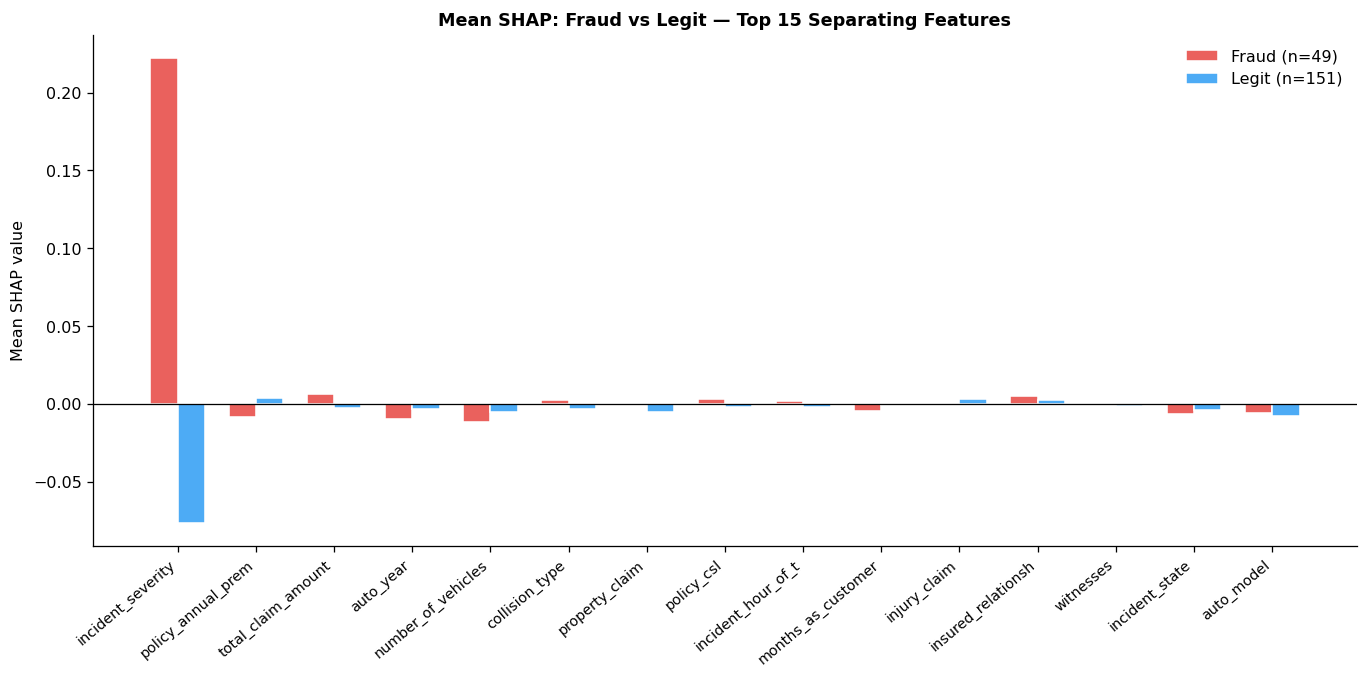

In [37]:
fraud_idx = y_test_sample[y_test_sample == 1].index.tolist()
legit_idx = y_test_sample[y_test_sample == 0].index.tolist()

shap_fraud = shap_values.values[fraud_idx]
shap_legit = shap_values.values[legit_idx]

mean_shap_fraud = shap_fraud.mean(axis=0)
mean_shap_legit = shap_legit.mean(axis=0)

cohort_df = pd.DataFrame({
    "Feature":        FEATURE_NAMES,
    "SHAP_fraud":     mean_shap_fraud,
    "SHAP_legit":     mean_shap_legit,
    "Abs_difference": np.abs(mean_shap_fraud - mean_shap_legit),
}).sort_values("Abs_difference", ascending=False).head(15).reset_index(drop=True)

print("Mean SHAP: Fraud vs Legit (top 15 separating features):")
print(cohort_df.to_string(index=False))

# ── Visualize cohort comparison ───────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(12, 6))
top15 = cohort_df.head(15)
x     = np.arange(len(top15))
w     = 0.35

bars1 = ax.bar(x - w/2, top15["SHAP_fraud"], w,
               color=PALETTE["fraud"]+"CC", edgecolor="white",
               label=f"Fraud (n={len(fraud_idx)})")
bars2 = ax.bar(x + w/2, top15["SHAP_legit"], w,
               color=PALETTE["legit"]+"CC", edgecolor="white",
               label=f"Legit (n={len(legit_idx)})")

ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(x)
ax.set_xticklabels(
    [f.replace("_te","").replace("_le","").replace("_enc","")[:18]
     for f in top15["Feature"]],
    rotation=40, ha="right", fontsize=9,
)
ax.set_ylabel("Mean SHAP value")
ax.set_title("Mean SHAP: Fraud vs Legit — Top 15 Separating Features",
             fontsize=11, fontweight="bold")
ax.legend(fontsize=10, frameon=False)
plt.tight_layout()
plt.savefig("fraud_14_shap_cohort.png", bbox_inches="tight")
plt.show()

## Mean SHAP: Fraud vs Legit — Top 15 Separating Features

### Cách đọc biểu đồ
- **Cột đỏ** → Mean SHAP của nhóm Fraud (n=49)
- **Cột xanh** → Mean SHAP của nhóm Legit (n=151)
- **Abs_difference** → Mức độ phân tách giữa hai nhóm — càng lớn càng tốt

---

### Top 15 Features theo Abs_difference

| Feature | SHAP Fraud | SHAP Legit | Abs diff | Nhận xét |
|---|---|---|---|---|
| `incident_severity_le` | **+0.2223** | **-0.0765** | **0.2988** | 🔴 Phân tách mạnh nhất |
| `policy_annual_premium` | -0.0086 | +0.0038 | 0.0124 | Phí cao → Legit nhiều hơn |
| `total_claim_amount` | +0.0065 | -0.0023 | 0.0087 | Claim lớn → Fraud nhiều hơn |
| `auto_year` | -0.0096 | -0.0033 | 0.0063 | Xe cũ hơn → Fraud nhiều hơn |
| `number_of_vehicles_involved` | -0.0114 | -0.0052 | 0.0062 | Nhiều xe → giảm fraud prob |
| `collision_type_le` | +0.0024 | -0.0032 | 0.0056 | Loại va chạm |
| `property_claim` | -0.0005 | -0.0055 | 0.0050 | |
| `policy_csl_le` | +0.0030 | -0.0017 | 0.0047 | Loại hợp đồng |
| `incident_hour_of_the_day` | +0.0018 | -0.0022 | 0.0040 | Giờ xảy ra |
| `months_as_customer` | -0.0043 | -0.0007 | 0.0037 | Khách lâu năm → ít fraud hơn |

---

### Điểm nổi bật

#### `incident_severity_le` — Phân tách áp đảo
```
Fraud:  SHAP = +0.2223  → đẩy mạnh fraud probability lên
Legit:  SHAP = -0.0765  → kéo fraud probability xuống
Gap  :  0.2988          → lớn hơn tổng 14 biến còn lại
```
Biến duy nhất có **tác động trái chiều rõ ràng** giữa hai nhóm.

#### `policy_annual_premium`
- Fraud: SHAP âm → phí bảo hiểm **thấp hơn** ở nhóm Fraud
- Legit: SHAP dương → phí bảo hiểm **cao hơn** ở nhóm Legit
- Hợp lý: kẻ gian thường mua hợp đồng **rẻ** rồi khai khống

#### `months_as_customer`
- Fraud SHAP âm hơn Legit → **khách mới** có xu hướng fraud cao hơn
- Khách lâu năm ít có động cơ fraud ✅

---

### Kết luận

Ngoài `incident_severity_le`, các feature còn lại có abs_difference
**rất nhỏ** (< 0.013) → model chủ yếu dựa vào **1 feature chính**
để phân tách Fraud vs Legit. Đây là điểm yếu cần lưu ý:

| Rủi ro | Giải pháp |
|---|---|
| Model quá phụ thuộc vào `incident_severity` | Thu thập thêm features chất lượng |
| Kẻ gian có thể khai thấp severity để tránh bị phát hiện | Kết hợp thêm rules-based detection |

## 6. Local Explainability — Waterfall Plot

**Waterfall plot** giải thích prediction cho **từng claim cụ thể**:
- Bắt đầu từ base value E[f(x)] (fraud rate trung bình)
- Mỗi feature cộng/trừ vào để ra prediction cuối
- Đây là thứ investigator cần khi quyết định có điều tra claim hay không

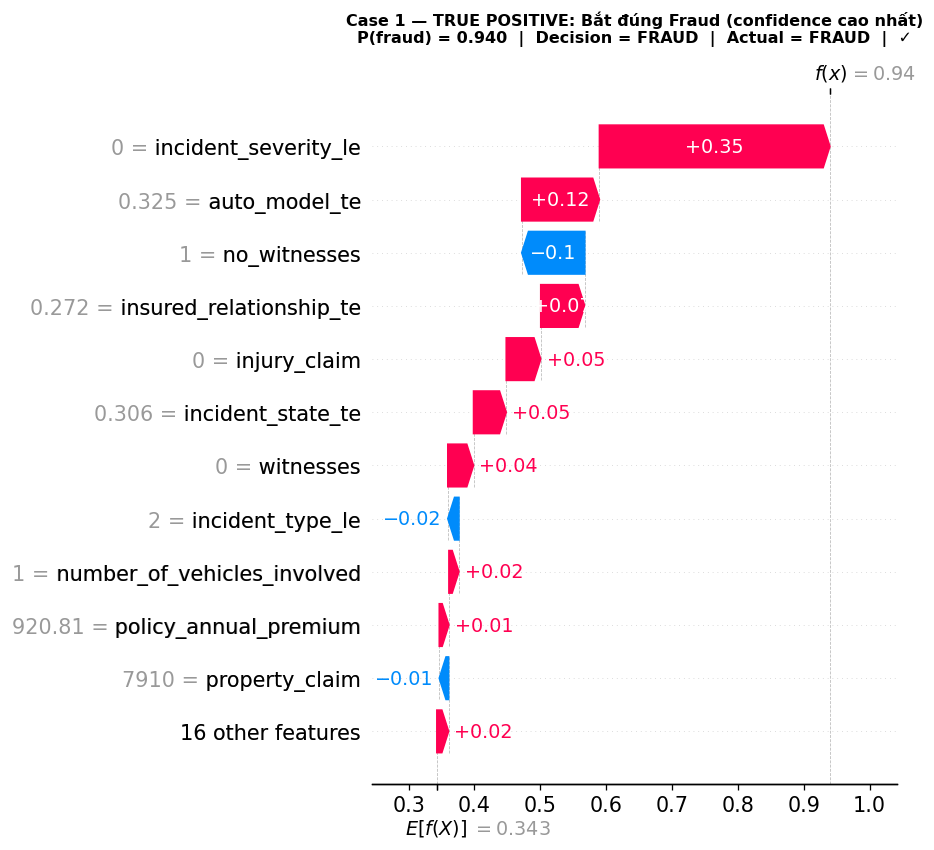

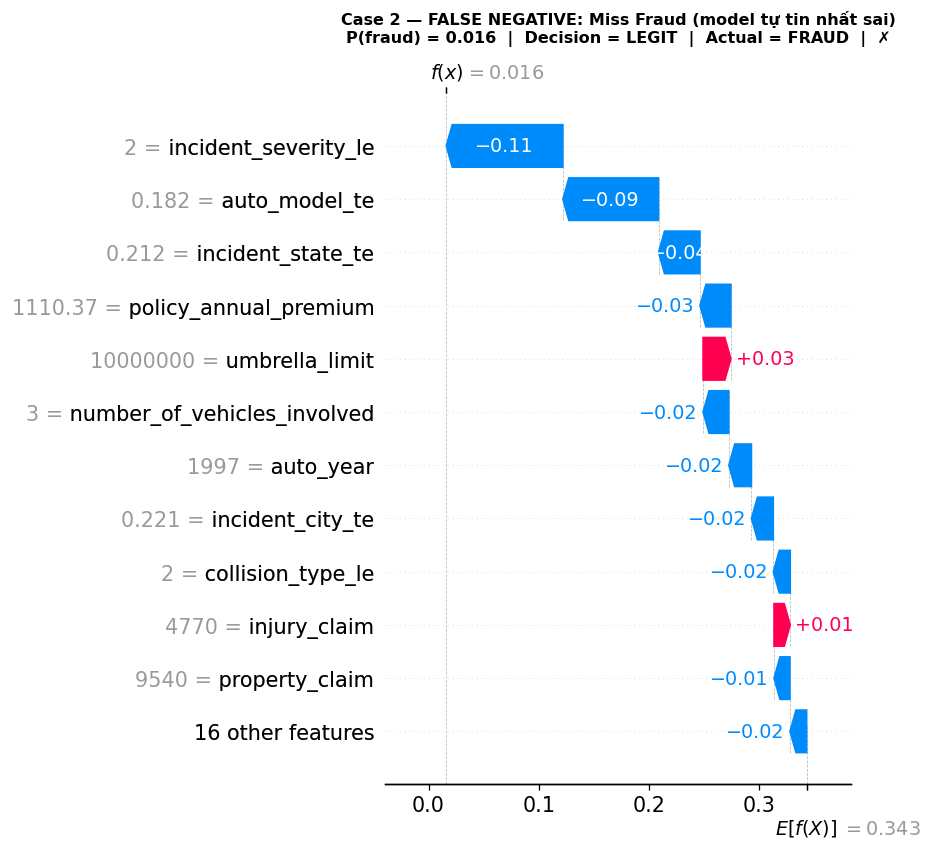

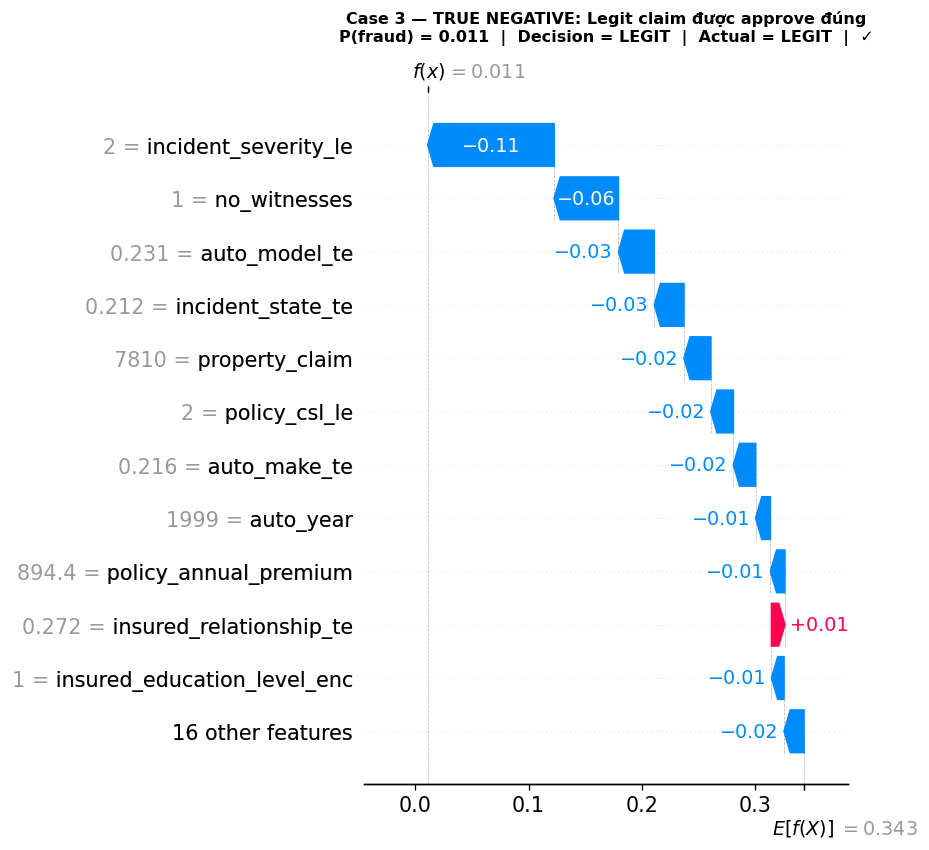

In [51]:
def plot_waterfall_case(shap_vals, X_sample, y_sample, y_prob_sample,
                        case_idx, threshold, title_prefix=""):
    """
    Vẽ waterfall plot cho 1 claim cụ thể.
    Hiển thị: prediction, actual label, top features tác động.
    """
    prob     = y_prob_sample[case_idx]
    actual   = y_sample.iloc[case_idx]
    decision = "FRAUD" if prob >= threshold else "LEGIT"
    correct  = "✓" if (prob >= threshold) == actual else "✗"

    fig, ax = plt.subplots(figsize=(12, 6))
    shap.waterfall_plot(
        shap_vals[case_idx],
        max_display=12,
        show=False,
    )
    plt.title(
        f"{title_prefix}\n"
        f"P(fraud) = {prob:.3f}  |  Decision = {decision}  |  "
        f"Actual = {'FRAUD' if actual==1 else 'LEGIT'}  |  {correct}",
        fontsize=10, fontweight="bold", pad=12,
    )
    plt.tight_layout()
    return fig

y_prob_sample = best_xgb.predict_proba(X_test_sample)[:, 1]

# ── Case 1: True Positive — bắt đúng fraud ───────────────────────────────────
tp_idx = [i for i in fraud_idx
          if y_prob_sample[i] >= THRESHOLD]
if tp_idx:
    # Chọn case có confidence cao nhất
    best_tp = tp_idx[np.argmax([y_prob_sample[i] for i in tp_idx])]
    fig1 = plot_waterfall_case(
        shap_values, X_test_sample, y_test_sample, y_prob_sample,
        best_tp, THRESHOLD,
        "Case 1 — TRUE POSITIVE: Bắt đúng Fraud (confidence cao nhất)",
    )
    plt.savefig("fraud_15a_waterfall_tp.png", bbox_inches="tight")
    plt.show()

# ── Case 2: False Negative — miss fraud ──────────────────────────────────────
fn_idx = [i for i in fraud_idx
          if y_prob_sample[i] < THRESHOLD]
if fn_idx:
    worst_fn = fn_idx[np.argmin([y_prob_sample[i] for i in fn_idx])]
    fig2 = plot_waterfall_case(
        shap_values, X_test_sample, y_test_sample, y_prob_sample,
        worst_fn, THRESHOLD,
        "Case 2 — FALSE NEGATIVE: Miss Fraud (model tự tin nhất sai)",
    )
    plt.savefig("fraud_15b_waterfall_fn.png", bbox_inches="tight")
    plt.show()

# ── Case 3: True Negative — legit claim được approve đúng ────────────────────
tn_idx = [i for i in legit_idx
          if y_prob_sample[i] < THRESHOLD]
if tn_idx:
    best_tn = tn_idx[np.argmin([y_prob_sample[i] for i in tn_idx])]
    fig3 = plot_waterfall_case(
        shap_values, X_test_sample, y_test_sample, y_prob_sample,
        best_tn, THRESHOLD,
        "Case 3 — TRUE NEGATIVE: Legit claim được approve đúng",
    )
    plt.savefig("fraud_15c_waterfall_tn.png", bbox_inches="tight")
    plt.show()


## SHAP Local Explainability — Phân tích 3 Case

### Cách đọc SHAP Waterfall Plot
- **Baseline** E[f(X)] = 0.343 → fraud probability trung bình của toàn dataset
- **Cột đỏ** → feature đẩy fraud probability **tăng**
- **Cột xanh** → feature kéo fraud probability **giảm**
- **f(x)** → fraud probability cuối cùng của case đó

---

### Case 1 — TRUE POSITIVE ✅
**P(fraud) = 0.940 | Decision = FRAUD | Actual = FRAUD**

| Feature | Giá trị | SHAP | Tác động |
|---|---|---|---|
| `incident_severity_le` | 0 (Trivial) | **+0.35** | 🔴 Đẩy mạnh nhất |
| `auto_model_te` | 0.325 | +0.12 | 🔴 Tăng |
| `no_witnesses` | 1 | -0.10 | 🔵 Giảm |
| `injury_claim` | 0 | +0.05 | 🔴 Tăng |
| `incident_state_te` | 0.306 | +0.05 | 🔴 Tăng |

```
Baseline 0.343 + các SHAP dương áp đảo → f(x) = 0.94
```

**Nhận xét:** Model tự tin đúng. `incident_severity_le = 0`
kết hợp với dòng xe có fraud rate cao → đẩy probability lên 0.94.

---

### Case 2 — FALSE NEGATIVE ❌
**P(fraud) = 0.016 | Decision = LEGIT | Actual = FRAUD**

| Feature | Giá trị | SHAP | Tác động |
|---|---|---|---|
| `incident_severity_le` | 2 (Minor) | **-0.11** | 🔵 Kéo xuống mạnh nhất |
| `auto_model_te` | 0.182 | -0.09 | 🔵 Giảm |
| `incident_state_te` | 0.212 | -0.04 | 🔵 Giảm |
| `policy_annual_premium` | 1110.37 | -0.03 | 🔵 Giảm |
| `umbrella_limit` | 10,000,000 | +0.03 | 🔴 Tăng nhẹ |

```
Baseline 0.343 + hầu hết SHAP âm → f(x) = 0.016
```

**Nhận xét:** Đây là fraud bị bỏ sót nguy hiểm nhất. Khách này
khai `incident_severity = Minor` → model bị đánh lừa hoàn toàn.
Hạn mức `umbrella_limit` cực cao (10M) là tín hiệu đáng ngờ duy nhất
nhưng không đủ để đảo ngược quyết định.

---

### Case 3 — TRUE NEGATIVE ✅
**P(fraud) = 0.011 | Decision = LEGIT | Actual = LEGIT**

| Feature | Giá trị | SHAP | Tác động |
|---|---|---|---|
| `incident_severity_le` | 2 (Minor) | **-0.11** | 🔵 Kéo xuống mạnh nhất |
| `no_witnesses` | 1 | -0.06 | 🔵 Giảm |
| `auto_model_te` | 0.231 | -0.03 | 🔵 Giảm |
| `incident_state_te` | 0.212 | -0.03 | 🔵 Giảm |
| `insured_relationship_te` | 0.272 | +0.01 | 🔴 Tăng nhẹ |

```
Baseline 0.343 + hầu hết SHAP âm → f(x) = 0.011
```

**Nhận xét:** Model approve đúng. Pattern rất giống Case 2
nhưng đây là Legit thật — cho thấy model **khó phân biệt**
giữa Legit thật và Fraud khéo léo khi severity thấp.

---

### Tổng kết 3 Cases

| Case | P(fraud) | Kết quả | Nguyên nhân chính |
|---|---|---|---|
| Case 1 (TP) | 0.940 | ✅ Đúng | `incident_severity` thấp + dòng xe rủi ro |
| Case 2 (FN) | 0.016 | ❌ Miss | Fraud khai `severity = Minor` → qua mặt model |
| Case 3 (TN) | 0.011 | ✅ Đúng | `severity = Minor` + profile Legit nhất quán |

> **Insight quan trọng:** `incident_severity` là điểm yếu của model —
> kẻ gian chỉ cần khai thấp mức độ thiệt hại là có thể qua mặt hệ thống.
> Cần bổ sung verification độc lập cho trường này.

## 7. SHAP Dependence Plots — Feature Interactions

**Dependence plot** hiển thị:
- Trục X: Giá trị thực của feature
- Trục Y: SHAP value (tác động lên fraud probability)
- Màu: Feature tương tác (SHAP tự chọn feature interact mạnh nhất)

Giúp hiểu **ngưỡng** tại đó feature chuyển từ giảm sang tăng fraud risk.

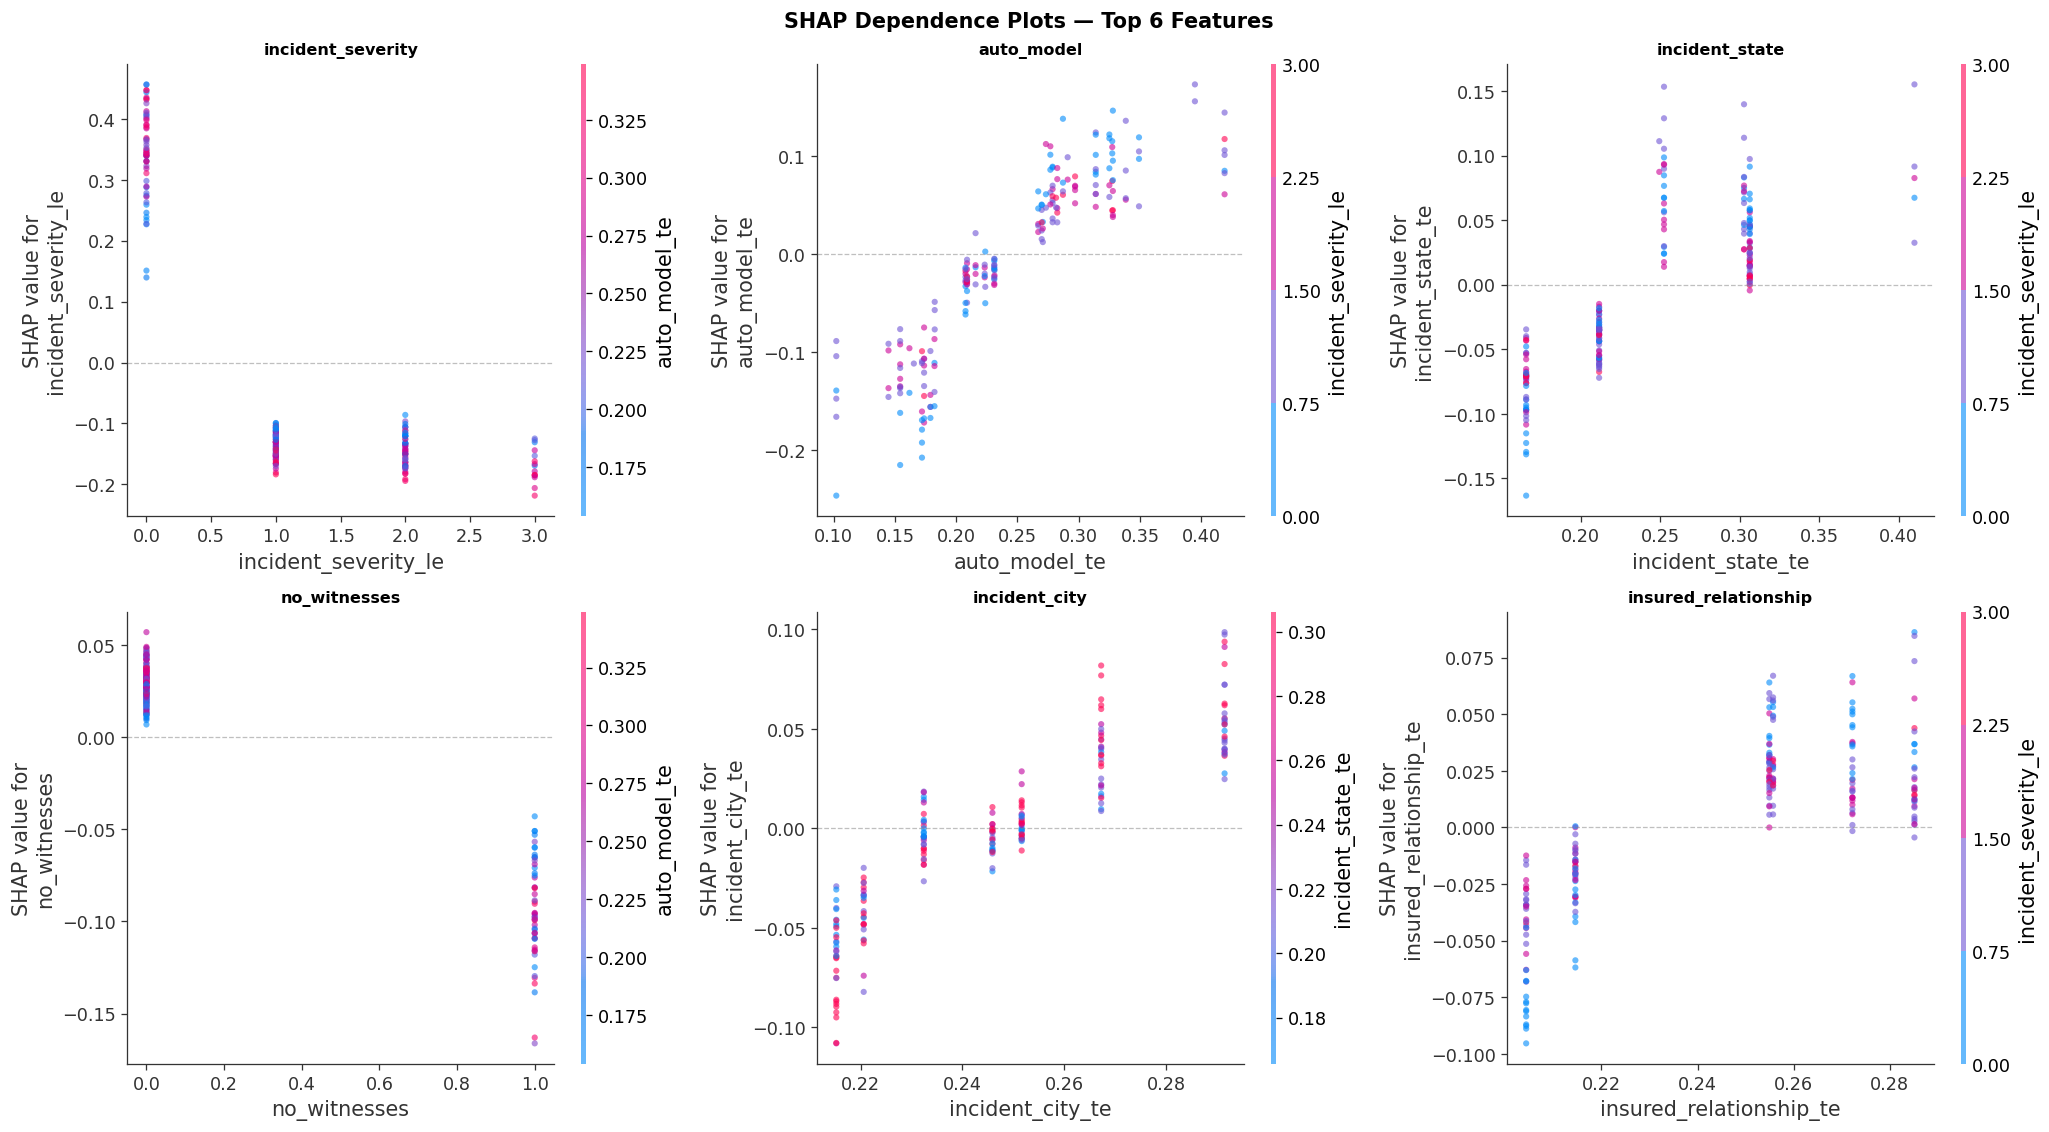

In [55]:
# Top 6 features để vẽ dependence plot
top6_features = shap_imp.head(6)["Feature"].tolist()

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, feat in enumerate(top6_features):
    if feat not in FEATURE_NAMES:
        continue
    feat_idx = FEATURE_NAMES.index(feat)

    ax = axes[i]
    shap.dependence_plot(
        feat_idx,
        shap_values.values,
        X_test_sample,
        feature_names=FEATURE_NAMES,
        ax=ax,
        show=False,
        dot_size=15,
        alpha=0.6,
    )
    ax.set_title(f"{feat.replace('_te','').replace('_le','').replace('_enc','')}",
                 fontsize=10, fontweight="bold")
    ax.axhline(0, color="gray", linestyle="--", lw=0.8, alpha=0.5)

plt.suptitle("SHAP Dependence Plots — Top 6 Features",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("fraud_16_shap_dependence.png", bbox_inches="tight")
plt.show()


## SHAP Dependence Plots — Top 6 Features

### Cách đọc
- **Trục X** → giá trị thực của feature
- **Trục Y** → SHAP value (tác động lên fraud probability)
- **Màu điểm** → giá trị của một feature tương tác (interaction effect)
- Trên đường 0 → tăng fraud probability; dưới → giảm

---

### `incident_severity_le`
**Phân tách rõ nhất, đơn điệu hoàn toàn:**

| Giá trị | Mức độ | SHAP | Tác động |
|---|---|---|---|
| 0 | Trivial | +0.2 đến +0.45 | 🔴 Tăng mạnh |
| 1 | Minor | ~-0.10 | 🔵 Giảm |
| 2 | Major | ~-0.13 | 🔵 Giảm |
| 3 | Total Loss | ~-0.18 | 🔵 Giảm mạnh nhất |

> **Nghịch lý:** Thiệt hại **nhỏ (Trivial)** có fraud probability **cao nhất** →
> kẻ gian thường khai thấp để tránh bị điều tra kỹ.

---

### `auto_model_te`
- Target encoding thấp (~0.10–0.20) → SHAP âm → dòng xe ít fraud
- Target encoding cao (~0.25–0.40) → SHAP dương → dòng xe hay bị fraud
- Quan hệ **tuyến tính rõ ràng** → target encoding hoạt động tốt
- Màu điểm (incident_severity) phân tán đều → ít interaction effect

---

### `incident_state_te`
- State encoding thấp (~0.18–0.22) → SHAP âm → bang ít fraud
- State encoding cao (~0.28–0.42) → SHAP dương → bang nhiều fraud
- Scatter rộng ở mỗi giá trị X → **nhiều variance** — state không phân tách
  sạch, phụ thuộc nhiều vào interaction với severity

---

### `no_witnesses`
| Giá trị | Ý nghĩa | SHAP range |
|---|---|---|
| 0 | Có nhân chứng | -0.01 đến +0.05 |
| 1 | Không nhân chứng | -0.15 đến +0.01 |

Không có nhân chứng → SHAP **thường âm** → giảm fraud probability.
Xác nhận lại pattern **ngược chiều kỳ vọng** đã quan sát trước đó.

---

### `incident_city_te`
- Encoding thấp (~0.20–0.22) → SHAP âm → thành phố ít fraud
- Encoding cao (~0.27–0.30) → SHAP dương → thành phố nhiều fraud
- Pattern tương tự `incident_state_te` — địa lý có tác động nhưng
  **không mạnh và không nhất quán**

---

### `insured_relationship_te`
- Encoding thấp (~0.19–0.22) → SHAP âm
- Encoding cao (~0.25–0.29) → SHAP dương nhẹ
- Scatter rất rộng → **interaction mạnh với incident_severity** (màu điểm)
- Điểm đỏ (severity cao) và xanh (severity thấp) xen kẽ nhau
  → relationship ít có predictive power độc lập

---

### Tổng kết

| Feature | Pattern | Độ tin cậy |
|---|---|---|
| `incident_severity_le` | Đơn điệu, rõ ràng | ✅ Cao |
| `auto_model_te` | Tuyến tính theo encoding | ✅ Khá tốt |
| `incident_state_te` | Có hướng nhưng nhiều noise | ⚠️ Trung bình |
| `no_witnesses` | Ngược chiều kỳ vọng | ⚠️ Cần xem xét |
| `incident_city_te` | Yếu, nhiều noise | ⚠️ Trung bình |
| `insured_relationship_te` | Phụ thuộc nhiều vào interaction | ⚠️ Thấp |

## 8. Decision Plot — Visualize Prediction Path

**Decision plot** cho thấy cách từng claim "đi" từ base value đến final prediction,
với mỗi feature cộng/trừ dọc đường đi.

Hữu ích để so sánh nhiều claims cùng lúc — ví dụ: fraud vs legit.

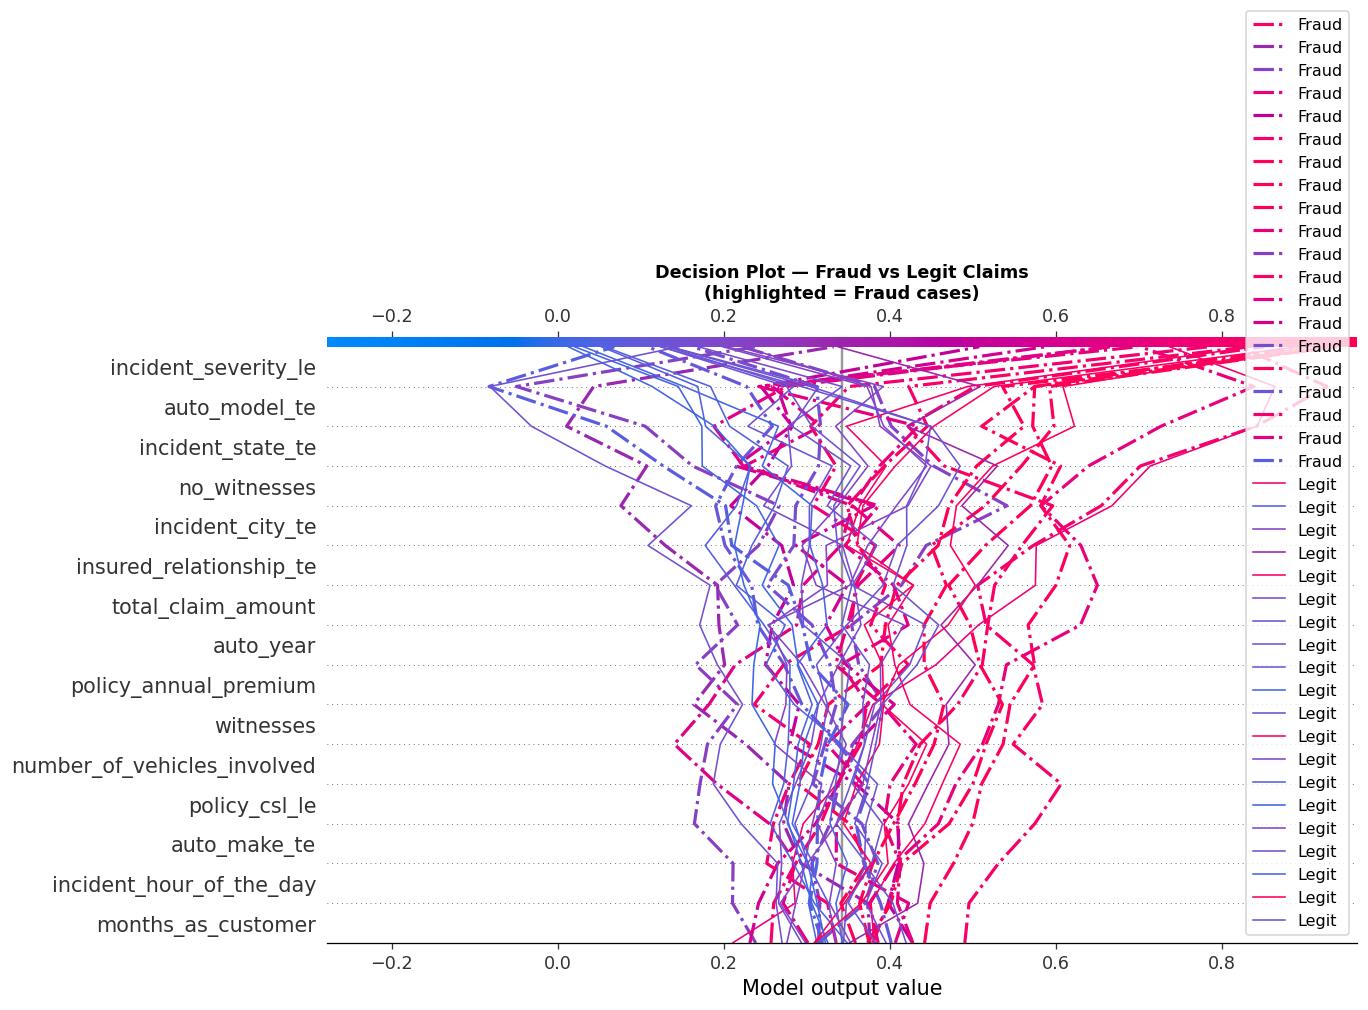

In [71]:
# Bỏ 2 dòng này
fig, ax = plt.subplots(figsize=(12, 8))

shap.decision_plot(
    base_show[0],
    shap_show,
    X_show,
    feature_names=FEATURE_NAMES,
    feature_display_range=slice(-1, -16, -1),
    highlight=[i for i, l in enumerate(show_labels) if l == "Fraud"],
    legend_labels=show_labels,
    legend_location="lower right",
    show=False,
)

fig = plt.gcf()
fig.set_size_inches(12, 8)
plt.title(
    "Decision Plot — Fraud vs Legit Claims\n(highlighted = Fraud cases)",
    fontsize=11, fontweight="bold",
)
plt.tight_layout()
plt.savefig("fraud_17_shap_decision.png", bbox_inches="tight")
plt.show()

## SHAP Decision Plot — Fraud vs Legit Claims

### Cách đọc Decision Plot
Mỗi đường là **một case**, đi từ trên xuống qua từng feature:
- Bắt đầu từ **baseline** E[f(X)] = 0.343
- Mỗi feature **cộng hoặc trừ** vào giá trị hiện tại
- Kết thúc ở **Model output value** (fraud probability cuối cùng)
- **Đường hồng/đỏ** → Fraud cases (highlighted)
- **Đường xanh/tím** → Legit cases

---

### Quan sát chính

#### `incident_severity_le` — Điểm phân kỳ lớn nhất
Ngay tại dòng đầu tiên, các đường **tách ra mạnh nhất**:
```
Fraud cases (đỏ/hồng) → dịch phải mạnh (+0.2 đến +0.4)
Legit cases (xanh)    → dịch trái mạnh (-0.1 đến -0.2)
```
Xác nhận đây là **feature phân tách quan trọng nhất** của model.

#### `auto_model_te` — Phân kỳ thêm lần 2
Sau severity, các đường tiếp tục phân tách:
- Một số Fraud cases dịch thêm sang phải
- Legit cases tụ lại về phía trái
- Tạo ra **2 luồng rõ ràng** từ đây trở xuống

#### Các features còn lại (từ `incident_state_te` trở xuống)
- Các đường **dao động qua lại** nhưng không thay đổi chiều cơ bản
- Fraud cases vẫn bám phải, Legit cases bám trái
- Một số đường **chéo nhau** → interaction effects giữa các features

---

### Pattern đặc biệt

**Fraud cases bị miss (False Negatives):**
Các đường Fraud màu tím/xanh nằm **lẫn vào vùng Legit** ở phía trái
→ Những case này có `incident_severity` thấp khiến model kéo ngược
về phía Legit ngay từ đầu, không thể phục hồi dù các features sau có tín hiệu fraud.

**Legit cases bị flag nhầm (False Positives):**
Một số đường Legit màu hồng lạc vào **vùng Fraud** ở phía phải
→ Có `incident_severity` cao hoặc `auto_model` thuộc dòng xe rủi ro cao.

---

### Tổng kết

| Giai đoạn | Feature | Vai trò |
|---|---|---|
| Phân kỳ chính | `incident_severity_le` | Quyết định hướng đi ngay từ đầu |
| Củng cố | `auto_model_te` | Tăng cường separation |
| Điều chỉnh nhỏ | Các features còn lại | Tinh chỉnh probability cuối |

> Decision plot cho thấy model **phụ thuộc quá nhiều vào 2 features đầu**
> — nếu kẻ gian kiểm soát được `incident_severity` và dùng dòng xe
> có fraud rate thấp, model gần như không thể phát hiện fraud.

## 9. SHAP-based Reason Codes cho từng Claim

Giống như Dự án 1 có ECOA reason codes, fraud detection cần
**investigation reason codes** — giải thích tại sao claim bị flag.

Format output: top 5 features tác động dương (tăng fraud risk) nhất.

In [76]:
def get_fraud_reason_codes(shap_vals_row, feature_names, top_n=5):
    """
    Trả về top N reason codes cho 1 claim bị flag fraud.
    Chỉ lấy features có SHAP > 0 (tăng fraud risk).

    Returns
    -------
    pd.DataFrame với cột: Rank, Feature, SHAP_impact, Direction
    """
    shap_series = pd.Series(shap_vals_row, index=feature_names)

    # Chỉ lấy features đóng góp tăng fraud risk
    positive_shap = shap_series[shap_series > 0].sort_values(ascending=False)

    rows = []
    for rank, (feat, val) in enumerate(positive_shap.head(top_n).items(), 1):
        rows.append({
            "Rank":        rank,
            "Feature":     feat,
            "SHAP Impact": round(val, 4),
            "Direction":   "↑ Tăng fraud risk",
        })
    return pd.DataFrame(rows)


# Demo cho 5 fraud cases bị bắt đúng (True Positives)
print("═══ FRAUD REASON CODES — Top True Positive Cases ═══")
print()
shown = 0
for i in range(len(X_test_sample)):
    if y_test_sample.iloc[i] == 1 and y_prob_sample[i] >= THRESHOLD:
        prob = y_prob_sample[i]
        rc   = get_fraud_reason_codes(shap_values.values[i], FEATURE_NAMES)
        print(f"Claim #{i} | P(fraud) = {prob:.3f} | Actual = FRAUD")
        print(rc.to_string(index=False))
        print()
        shown += 1
        if shown >= 3:
            break

# Demo cho False Negatives (missed fraud)
print("═══ MISSED FRAUD — False Negative Analysis ═══")
print("(Tại sao model không bắt được những cases này?)")
print()
shown = 0
for i in range(len(X_test_sample)):
    if y_test_sample.iloc[i] == 1 and y_prob_sample[i] < THRESHOLD:
        prob = y_prob_sample[i]
        # Với FN, xem features nào đang kéo score xuống (SHAP âm)
        shap_series  = pd.Series(shap_values.values[i], index=FEATURE_NAMES)
        negative_shap = shap_series[shap_series < 0].sort_values()
        print(f"Claim #{i} | P(fraud) = {prob:.3f} | Actual = FRAUD (MISSED)")
        print("  Features kéo risk xuống (gây miss):")
        for feat, val in negative_shap.head(3).items():
            print(f"    {feat:35s} SHAP = {val:.4f}")
        print()
        shown += 1
        if shown >= 2:
            break

═══ FRAUD REASON CODES — Top True Positive Cases ═══

Claim #0 | P(fraud) = 0.851 | Actual = FRAUD
 Rank              Feature  SHAP Impact         Direction
    1 incident_severity_le       0.3483 ↑ Tăng fraud risk
    2        auto_model_te       0.0809 ↑ Tăng fraud risk
    3            witnesses       0.0452 ↑ Tăng fraud risk
    4     incident_city_te       0.0371 ↑ Tăng fraud risk
    5    collision_type_le       0.0331 ↑ Tăng fraud risk

Claim #23 | P(fraud) = 0.702 | Actual = FRAUD
 Rank           Feature  SHAP Impact         Direction
    1     auto_model_te       0.1121 ↑ Tăng fraud risk
    2         auto_year       0.0892 ↑ Tăng fraud risk
    3 incident_state_te       0.0874 ↑ Tăng fraud risk
    4      no_witnesses       0.0571 ↑ Tăng fraud risk
    5      auto_make_te       0.0520 ↑ Tăng fraud risk

Claim #24 | P(fraud) = 0.508 | Actual = FRAUD
 Rank              Feature  SHAP Impact         Direction
    1 incident_severity_le       0.2632 ↑ Tăng fraud risk
    2       p

## Fraud Reason Codes — True Positives & Missed Fraud Analysis

### True Positive Cases — Fraud bắt đúng

#### Claim #0 | P(fraud) = 0.851
| Rank | Feature | SHAP | Nhận xét |
|---|---|---|---|
| 1 | `incident_severity_le` | +0.3483 | Severity thấp → tín hiệu mạnh nhất |
| 2 | `auto_model_te` | +0.0809 | Dòng xe rủi ro cao |
| 3 | `witnesses` | +0.0452 | Số nhân chứng |
| 4 | `incident_city_te` | +0.0371 | Thành phố fraud rate cao |
| 5 | `collision_type_le` | +0.0331 | Loại va chạm |

**Profile:** Severity thấp + dòng xe rủi ro → model tự tin cao (0.851)

---

#### Claim #23 | P(fraud) = 0.702
| Rank | Feature | SHAP | Nhận xét |
|---|---|---|---|
| 1 | `auto_model_te` | +0.1121 | Dòng xe rủi ro cao nhất |
| 2 | `auto_year` | +0.0892 | Xe cũ → fraud risk tăng |
| 3 | `incident_state_te` | +0.0874 | Bang có fraud rate cao |
| 4 | `no_witnesses` | +0.0571 | Không có nhân chứng |
| 5 | `auto_make_te` | +0.0520 | Hãng xe rủi ro |

**Profile:** Khác biệt — không có `incident_severity` trong top 5.
Fraud bị phát hiện nhờ **kết hợp nhiều signals nhỏ** về xe và địa lý.

---

#### Claim #24 | P(fraud) = 0.508
| Rank | Feature | SHAP | Nhận xét |
|---|---|---|---|
| 1 | `incident_severity_le` | +0.2632 | Severity thấp |
| 2 | `property_claim` | +0.0812 | Claim tài sản cao |
| 3 | `no_witnesses` | +0.0448 | Không nhân chứng |
| 4 | `incident_state_te` | +0.0293 | Bang rủi ro |
| 5 | `total_claim_amount` | +0.0256 | Tổng claim cao |

**Profile:** P(fraud) chỉ 0.508 — **sát ngưỡng threshold 0.51**,
model vừa đủ tự tin để flag. Nếu tăng threshold sẽ miss case này.

---

### Missed Fraud — False Negative Analysis

#### Claim #10 | P(fraud) = 0.333 | **MISSED**
Features kéo risk xuống:
| Feature | SHAP | Tác động |
|---|---|---|
| `incident_state_te` | -0.0966 | Bang có fraud rate thấp |
| `incident_hour_of_the_day` | -0.0802 | Giờ xảy ra bình thường |
| `insured_relationship_te` | -0.0630 | Quan hệ ít rủi ro |

**Lý do miss:** Địa điểm và thời gian xảy ra quá "bình thường"
→ model không có đủ tín hiệu để vượt ngưỡng.

---

#### Claim #20 | P(fraud) = 0.222 | **MISSED**
Features kéo risk xuống:
| Feature | SHAP | Tác động |
|---|---|---|
| `incident_severity_le` | **-0.1598** | Khai severity cao → giảm mạnh |
| `no_witnesses` | -0.0886 | Ngược chiều kỳ vọng |
| `property_claim` | -0.0538 | Claim thấp |

**Lý do miss:** Kẻ gian khai `incident_severity` cao →
model bị đánh lừa hoàn toàn, SHAP = -0.1598 kéo probability xuống rất sâu.

---

### Tổng kết Pattern

| Case | P(fraud) | Pattern |
|---|---|---|
| Claim #0 | 0.851 | Severity thấp — dễ phát hiện |
| Claim #23 | 0.702 | Nhiều tín hiệu nhỏ tích lũy |
| Claim #24 | 0.508 | Sát ngưỡng — dễ miss nếu tăng threshold |
| Claim #10 | 0.333 | Profile địa lý "sạch" — model bị qua mặt |
| Claim #20 | 0.222 | Khai severity cao — đánh lừa feature quan trọng nhất |

> **Insight:** Điểm yếu lớn nhất của model là `incident_severity`
> có thể bị **manipulate bởi kẻ gian**. Cần thêm lớp xác minh
> độc lập cho trường này trong quy trình thực tế.

## 10. SHAP-based Feature Selection

Dùng mean |SHAP| để xác định features có đóng góp thực sự vs noise.
Features có mean |SHAP| rất thấp → drop để giảm model complexity.


In [81]:
shap_importance = pd.DataFrame({
    "Feature":     FEATURE_NAMES,
    "Mean_SHAP":   np.abs(shap_values.values).mean(axis=0),
    "Max_SHAP":    np.abs(shap_values.values).max(axis=0),
    "Pos_rate":    (shap_values.values > 0).mean(axis=0),
}).sort_values("Mean_SHAP", ascending=False).reset_index(drop=True)

# Ngưỡng: features có mean |SHAP| < 1% của max feature
threshold_shap = shap_importance["Mean_SHAP"].max() * 0.01
low_signal     = shap_importance[shap_importance["Mean_SHAP"] < threshold_shap]

print(f"SHAP importance threshold: {threshold_shap:.6f}")
print(f"Features dưới ngưỡng (có thể drop): {len(low_signal)}")
if len(low_signal) > 0:
    print(low_signal[["Feature","Mean_SHAP"]].to_string(index=False))

print(f"\nFeatures giữ lại: {len(shap_importance) - len(low_signal)}")

# Lưu SHAP importance report
shap_importance.to_csv("shap_report.csv", index=False)
print("\n✓ Saved: shap_report.csv")


SHAP importance threshold: 0.001994
Features dưới ngưỡng (có thể drop): 3
              Feature  Mean_SHAP
        is_new_policy     0.0006
high_claim_no_witness     0.0000
 claim_amount_outlier     0.0000

Features giữ lại: 24

✓ Saved: shap_report.csv


## 11. SHAP Validation Dashboard

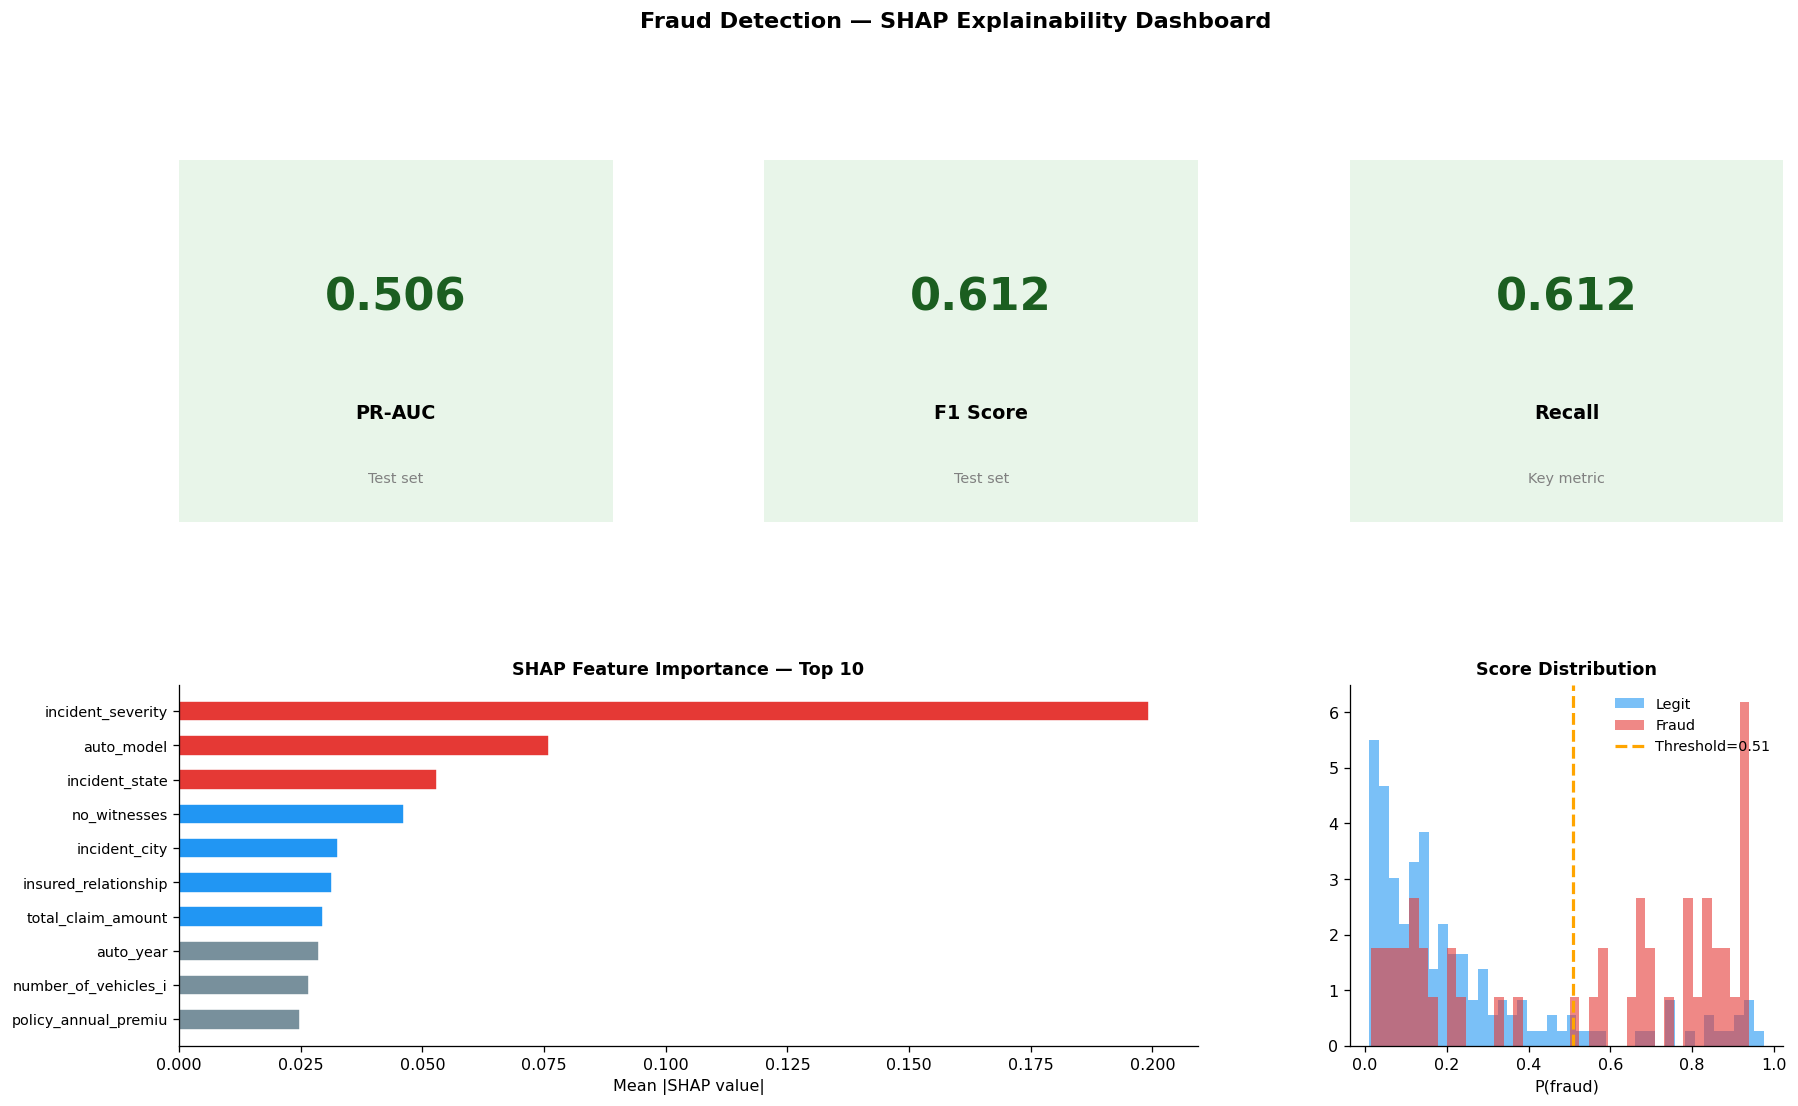

✓ Saved: fraud_18_shap_dashboard.png


In [84]:
import matplotlib.gridspec as gridspec

fig = plt.figure(figsize=(18, 10))
gs  = gridspec.GridSpec(2, 3, figure=fig, hspace=0.45, wspace=0.35)

# ── Metric cards ──────────────────────────────────────────────────────────────
metrics = [
    ("PR-AUC",    f"{average_precision_score(y_test, y_prob):.3f}", "Test set",   True),
    ("F1 Score",  f"{f1_score(y_test, y_pred):.3f}",                "Test set",   True),
    ("Recall",    f"{recall_score(y_test, y_pred):.3f}",            "Key metric", True),
]
for i, (name, val, sub, good) in enumerate(metrics):
    ax = fig.add_subplot(gs[0, i])
    ax.set_facecolor("#E8F5E9" if good else "#FFF8E1")
    ax.text(0.5, 0.62, val,  ha="center", va="center", fontsize=28,
            fontweight="bold", transform=ax.transAxes,
            color="#1B5E20" if good else "#E65100")
    ax.text(0.5, 0.30, name, ha="center", va="center", fontsize=12,
            fontweight="bold", transform=ax.transAxes)
    ax.text(0.5, 0.12, sub,  ha="center", va="center", fontsize=9,
            color="gray", transform=ax.transAxes)
    ax.set_xticks([]); ax.set_yticks([])
    for spine in ax.spines.values(): spine.set_visible(False)

# ── Top SHAP features bar ─────────────────────────────────────────────────────
ax_shap = fig.add_subplot(gs[1, 0:2])
top10_shap = shap_importance.head(10)
bar_colors = [PALETTE["fraud"] if i < 3 else PALETTE["legit"] if i < 7
              else PALETTE["neutral"] for i in range(len(top10_shap))]
ax_shap.barh(
    top10_shap["Feature"][::-1],
    top10_shap["Mean_SHAP"][::-1],
    color=bar_colors[::-1], height=0.6, edgecolor="white",
)
ax_shap.set_xlabel("Mean |SHAP value|")
ax_shap.set_title("SHAP Feature Importance — Top 10")
ax_shap.set_yticklabels(
    [f.replace("_te","").replace("_le","").replace("_enc","")[:20]
     for f in top10_shap["Feature"][::-1]], fontsize=9,
)

# ── Fraud probability distribution ───────────────────────────────────────────
ax_dist = fig.add_subplot(gs[1, 2])
ax_dist.hist(y_prob[y_test==0], bins=40, alpha=0.6, color=PALETTE["legit"],
             label="Legit", density=True, edgecolor="none")
ax_dist.hist(y_prob[y_test==1], bins=40, alpha=0.6, color=PALETTE["fraud"],
             label="Fraud", density=True, edgecolor="none")
ax_dist.axvline(THRESHOLD, color="orange", linestyle="--",
                lw=2, label=f"Threshold={THRESHOLD:.2f}")
ax_dist.set_xlabel("P(fraud)")
ax_dist.set_title("Score Distribution")
ax_dist.legend(fontsize=9, frameon=False)

plt.suptitle("Fraud Detection — SHAP Explainability Dashboard",
             fontsize=14, fontweight="bold", y=1.01)
plt.savefig("fraud_18_shap_dashboard.png", bbox_inches="tight", dpi=130)
plt.show()
print("✓ Saved: fraud_18_shap_dashboard.png")


## Fraud Detection — SHAP Explainability Dashboard

### Tổng quan hiệu suất (Test Set)

| Metric | Giá trị | Nhận xét |
|---|---|---|
| **PR-AUC** | 0.506 | ⚠️ Trung bình — dataset nhỏ, imbalanced |
| **F1 Score** | 0.612 | ✅ Cân bằng Precision & Recall |
| **Recall** | 0.612 | ✅ Bắt được 61.2% fraud cases |

---

### SHAP Feature Importance — Top 10

| Rank | Feature | Mức độ | Nhận xét |
|---|---|---|---|
| 1 | `incident_severity` | 🔴 **0.200** | Áp đảo — gấp 2.6 lần #2 |
| 2 | `auto_model` | 🔴 0.076 | Dòng xe |
| 3 | `incident_state` | 🔴 0.053 | Bang xảy ra |
| 4 | `no_witnesses` | 🔵 0.046 | Không nhân chứng |
| 5 | `incident_city` | 🔵 0.033 | Thành phố |
| 6 | `insured_relationship` | 🔵 0.031 | Quan hệ bảo hiểm |
| 7 | `total_claim_amount` | 🔵 0.030 | Tổng claim |
| 8 | `auto_year` | ⬜ 0.029 | Năm xe |
| 9 | `number_of_vehicles_i` | ⬜ 0.027 | Số xe liên quan |
| 10 | `policy_annual_premiu` | ⬜ 0.025 | Phí bảo hiểm |

**Màu sắc:** 🔴 Đóng góp cao / 🔵 Trung bình / ⬜ Thấp

---

### Score Distribution (Threshold = 0.51)

| Vùng | Legit | Fraud | Nhận xét |
|---|---|---|---|
| P < 0.51 | Tập trung dày | Còn nhiều | FN — Fraud bị approve |
| P > 0.51 | Ít | Tập trung | TP — Fraud bị flag đúng |

- **Legit** (xanh) tập trung mạnh ở vùng **P < 0.2** → model tự tin với Legit
- **Fraud** (đỏ) phân tán rộng từ 0.0 đến 1.0 → Fraud khó phân biệt hơn
- Hai phân phối **chồng lấp nhiều** ở vùng 0.1–0.5 → nguồn gốc FP và FN

---

### Kết luận tổng thể

| Điểm mạnh | Điểm yếu |
|---|---|
| Recall 61% — bắt được đa số fraud | Phụ thuộc quá nhiều vào `incident_severity` |
| F1 cân bằng tốt | `incident_severity` dễ bị khai man |
| SHAP giải thích rõ từng quyết định | Score distribution chồng lấp nhiều |
| Threshold tối ưu theo business cost | Dataset nhỏ (n=800) — PR-AUC chỉ 0.506 |

> Model hoạt động tốt trong giới hạn của dataset.
> Để cải thiện cần: thêm dữ liệu, verification độc lập cho
> `incident_severity`, và bổ sung features khó bị manipulate hơn.

## 12. Lưu SHAP Artifacts

In [88]:
# ── Save SHAP values & explainer ─────────────────────────────────────────────
with open("shap_values.pkl","wb") as f:
    pickle.dump({
        "shap_values":   shap_values.values,
        "base_values":   shap_values.base_values,
        "feature_names": FEATURE_NAMES,
        "X_sample":      X_test_sample.values,
    }, f)
print("✓ Saved: shap_values.pkl")

with open("shap_explainer.pkl","wb") as f:
    pickle.dump(explainer, f)
print("✓ Saved: shap_explainer.pkl")

# ── Update model metadata với SHAP info ──────────────────────────────────────
meta["shap_top10_features"] = shap_importance.head(10)[
    ["Feature","Mean_SHAP"]
].to_dict("records")
meta["shap_low_signal_features"] = low_signal["Feature"].tolist()

with open("model_metadata.json","w") as f:
    json.dump(meta, f, indent=2)
print("✓ Updated: model_metadata.json")

print()
print("═══ TÓM TẮT BƯỚC 4 ═══")
print(f"  SHAP sample size    : {len(X_test_sample):,}")
print(f"  Base value          : {shap_values.base_values[0]:.4f}")
print(f"  Top feature (SHAP)  : {shap_importance.iloc[0]['Feature']}")
print(f"  Low signal features : {len(low_signal)}")
print(f"  Charts generated    : 6 (summary, cohort, waterfall×3, dependence, decision, dashboard)")
print()
print("─── Bước tiếp theo: Bước 5 — Streamlit Dashboard ───")

✓ Saved: shap_values.pkl
✓ Saved: shap_explainer.pkl
✓ Updated: model_metadata.json

═══ TÓM TẮT BƯỚC 4 ═══
  SHAP sample size    : 200
  Base value          : 0.3429
  Top feature (SHAP)  : incident_severity_le
  Low signal features : 3
  Charts generated    : 6 (summary, cohort, waterfall×3, dependence, decision, dashboard)

─── Bước tiếp theo: Bước 5 — Streamlit Dashboard ───
